# 🚗 Used Car Price Prediction — Improved Model

**Improvements over v1:**
- ✅ Random Forest instead of Linear Regression
- ✅ Trains on full dataset (not per-model subsets)
- ✅ `car_age` feature instead of raw year
- ✅ Log-transform on `selling_price` and `km_driven`
- ✅ Outlier removal (1st–99th percentile)
- ✅ Evaluation: R² score, MAE, RMSE, 5-fold cross-validation
- ✅ Interactive UI preserved with improved layout




### 📋 Notebook Summary

This notebook builds an end-to-end car price prediction pipeline using a Random Forest Regressor, wrapped in an interactive `ipywidgets` interface.

**Pipeline overview:**
1. **Setup** — loads pandas/numpy/sklearn/seaborn/ipywidgets for data handling, modeling, and interactive visualization
2. **Data loading** — reads the raw Car Dekho car listings CSV
3. **Preprocessing** — extracts car model from name, converts year to car age, log-transforms skewed features (`km_driven`, `selling_price`), removes price outliers (1st–99th percentile), and one-hot encodes categorical columns
4. **Model training** — trains a single Random Forest Regressor (150 trees, depth-capped) on the full dataset rather than per-model subsets, using an 80/20 train/test split
5. **Evaluation** — reports R² (log-scale), MAE/RMSE (actual ₹ scale), and validates robustness via 5-fold cross-validation
6. **Visualization** — plots actual vs predicted prices and top 15 feature importances
7. **Interactive UI** — builds dropdown/input widgets for model, year, fuel, transmission, seller type, owner, and KM driven
8. **Prediction engine** — validates the selected input combination against real data (to avoid predicting on combinations that never existed), builds the model input row, predicts price, and shows contextual price-trend plots for the selected car model

**Takeaway:** A practical regression pipeline that goes beyond just training a model — it includes real-world input validation and interpretability, making it usable as a live "estimate my car's price" tool rather than just a static analysis.

## Section 1: Importing Required Libraries

### 📦 Section: Library Imports & Setup

**Purpose:** Load all dependencies needed for a machine learning regression workflow with interactive visualization.

**Core libraries**
- `pandas`, `numpy` — data handling and numerical operations
- `ipywidgets` — interactive UI elements (sliders, dropdowns, buttons) inside the notebook
- `matplotlib.pyplot`, `seaborn` — plotting; seaborn adds statistical styling on top of matplotlib
- `IPython.display` (`display`, `clear_output`) — renders widgets/plots dynamically, used for refreshing interactive outputs

**Modeling libraries**
- `RandomForestRegressor` (sklearn.ensemble) — ensemble of decision trees for regression
- `train_test_split`, `cross_val_score` (sklearn.model_selection) — splitting data and evaluating via cross-validation

**Evaluation metrics**
- `r2_score` — variance in target explained by the model
- `mean_absolute_error` — average absolute error, same units as target
- `mean_squared_error` — penalizes larger errors more heavily

**Other**
- `warnings.filterwarnings('ignore')` — suppresses warning messages for cleaner output (note: can hide useful deprecation/data warnings)

**Takeaway:** Sets up the environment for training a Random Forest regression model, evaluating it, and building an interactive widget-based interface for exploring results.

In [17]:
import pandas as pd
import numpy as np
import ipywidgets as widgets
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, clear_output
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

print('✅ Libraries loaded successfully')


✅ Libraries loaded successfully


## Section 2: Loading the Dataset

### 📂 Section: Load Raw Dataset

**Purpose:** Read the raw car listings dataset into memory and get a first look at its structure.

**Breakdown**
- `pd.read_csv(...)` — loads the CSV file (Car Dekho car details dataset) from Colab's local storage (`/content/`) into a pandas DataFrame
- `df_raw.shape` — prints (rows, columns) to quickly confirm dataset size
- `df_raw.head(3)` — displays the first 3 rows to visually inspect column names, data types, and sample values

**Note:** This assumes the CSV has already been uploaded to the Colab session's `/content/` folder (or mounted from Drive). If the notebook is re-run in a fresh session, this file path won't persist and will need re-uploading.

**Takeaway:** Initial data ingestion step — confirms the dataset loaded correctly before any cleaning or preprocessing begins.

In [18]:
df_raw = pd.read_csv('/content/CAR DETAILS FROM CAR DEKHO.csv')
print(f'📊 Raw dataset shape: {df_raw.shape}')
display(df_raw.head(3))


📊 Raw dataset shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner


## Section 3: Feature Engineering & Preprocessing

### 🛠️ Section: Preprocessing Function

**Purpose:** Clean and transform the raw dataset into a model-ready format — handling feature extraction, skew correction, outlier removal, and encoding.

**Step-by-step breakdown**

- **`CURRENT_YEAR = 2024`** — reference year used to compute car age instead of using raw manufacturing year

- **Car Model extraction**
  - `df['name'].apply(...)` pulls the first 2 words of the `name` column (typically brand + model, e.g. "Maruti Swift") into a new `Car_Model` column
  - Original `name` column dropped since it's too granular/high-cardinality to use directly

- **Car age instead of year**
  - `car_age = CURRENT_YEAR - year` — converts an absolute year into a relative age, which is usually more predictive and generalizes better across time
  - Raw `year` column dropped after conversion

- **Log-transform `km_driven`**
  - `np.log1p(km_driven)` compresses large/skewed distance values, reducing the impact of extreme values and helping tree-based/linear models perform better

- **Log-transform target (`selling_price` → `log_price`)**
  - Same log1p transform applied to the target variable to reduce skew (price distributions are typically right-skewed)
  - Original `selling_price` dropped, `log_price` becomes the new target

- **Outlier removal**
  - Computes 1st and 99th percentile of `log_price`
  - Filters out rows outside this range — removes extreme low/high price outliers that could distort model training
  - **Note:** variable names `Q1`/`Q3` are misleading here — these are the 1st/99th percentiles, not the standard IQR quartiles (25th/75th). Worth renaming for clarity if this goes into a shared codebase

- **One-hot encoding**
  - `pd.get_dummies(...)` converts categorical columns (`fuel`, `seller_type`, `transmission`, `owner`, `Car_Model`) into binary indicator columns
  - `drop_first=True` drops one category per feature to avoid multicollinearity (dummy variable trap)

**Output:** Prints final sample count and feature count (excluding the target column) after preprocessing.

**Takeaway:** This function converts a messy, raw dataset into a numeric, model-ready DataFrame — handling high-cardinality text, skewed numeric features, outliers, and categorical variables in one pass.

In [19]:
CURRENT_YEAR = 2024

def preprocess(df):
    df = df.copy()

    # Extract car model (first 2 words)
    df['Car_Model'] = df['name'].apply(lambda x: ' '.join(str(x).split()[:2]))
    df.drop(columns=['name'], inplace=True)

    # ✅ car_age instead of raw year
    df['car_age'] = CURRENT_YEAR - df['year']
    df.drop(columns=['year'], inplace=True)

    # ✅ Log-transform km_driven to reduce skew
    df['km_driven'] = np.log1p(df['km_driven'])

    # ✅ Log-transform selling_price (target)
    df['log_price'] = np.log1p(df['selling_price'])
    df.drop(columns=['selling_price'], inplace=True)

    # ✅ Remove extreme price outliers (1st-99th percentile)
    Q1 = df['log_price'].quantile(0.01)
    Q3 = df['log_price'].quantile(0.99)
    df = df[(df['log_price'] >= Q1) & (df['log_price'] <= Q3)]

    # One-hot encode categoricals
    df = pd.get_dummies(
        df,
        columns=['fuel', 'seller_type', 'transmission', 'owner', 'Car_Model'],
        drop_first=True
    )
    return df

df = preprocess(df_raw)
print(f'✅ Processed dataset: {df.shape[0]} samples, {df.shape[1]-1} features')


✅ Processed dataset: 4255 samples, 191 features


## Section 4: Training the Random Forest Model

### 🌲 Section: Train/Test Split & Model Training

**Purpose:** Split the processed dataset into train/test sets and train a Random Forest Regressor on the full dataset.

**Breakdown**

- **Feature/target split**
  - `X = df.drop('log_price', axis=1)` — all columns except the target
  - `y = df['log_price']` — the log-transformed price, used as the regression target

- **Train/test split**
  - `train_test_split(..., test_size=0.2, random_state=42)` — 80/20 split
  - `random_state=42` ensures reproducibility across runs

- **Note on comment "Train on FULL dataset, not per-model subsets"**
  - This suggests an earlier/alternative approach trained separate models per car model (subsetting data), which likely led to too little data per subset. Training one model on the full dataset lets it learn shared patterns across all car models (with `Car_Model` as a one-hot feature instead)

- **Random Forest hyperparameters**
  - `n_estimators=150` — number of trees in the ensemble; more trees generally improve stability at the cost of compute
  - `max_depth=20` — caps how deep each tree can grow, controlling overfitting
  - `min_samples_split=4` — minimum samples required to split an internal node
  - `min_samples_leaf=2` — minimum samples required at a leaf node (prevents overly specific leaves)
  - `random_state=42` — reproducibility of tree construction
  - `n_jobs=-1` — uses all available CPU cores to parallelize training

- **`rf_model.fit(X_train, y_train)`** — trains the model on the training split

**Takeaway:** A single Random Forest model is trained on the entire dataset (rather than fragmented per-car-model subsets), using moderately regularized hyperparameters to balance fit and overfitting risk.

In [20]:
# ✅ Train on FULL dataset, not per-model subsets
X = df.drop('log_price', axis=1)
y = df['log_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ✅ Random Forest Regressor
print('🌲 Training Random Forest (this may take ~30 seconds)...')
rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=20,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
print('✅ Model trained!')


🌲 Training Random Forest (this may take ~30 seconds)...
✅ Model trained!


## Section 5: Evaluation — R², MAE, RMSE, Cross-Validation

### 📊 Section: Model Evaluation & Cross-Validation

**Purpose:** Evaluate the trained Random Forest model on the test set using multiple metrics, then validate reliability with 5-fold cross-validation.

**Prediction & inverse transform**
- `rf_model.predict(X_test)` — generates predictions in log-space (`y_pred_log`), since the model was trained on `log_price`
- `np.expm1(...)` — inverts the earlier `log1p` transform, converting predictions and true test values back to actual price scale (`y_pred_actual`, `y_test_actual`)

**Metrics**
- `r2_score(y_test, y_pred_log)` — R² computed in **log-space** (not actual price space); measures how well the model explains variance in log-transformed prices
- `mean_absolute_error(y_test_actual, y_pred_actual)` — MAE computed in **actual price space** (₹), giving an interpretable average error magnitude
- `mean_squared_error(...)` → `rmse` — also computed in actual price space; penalizes large errors more than MAE

**Note:** R² is on log scale while MAE/RMSE are on actual price scale — this is intentional (R² is more stable/meaningful in log-space since the model was trained there), but worth flagging since it's a mixed-scale evaluation report — good to state explicitly if this goes into a written report.

**Report printout**
- Formatted console output summarizing R², MAE, RMSE
- Conditional check: flags whether R² crosses an 80% threshold as an informal "good enough" benchmark

**Cross-validation**
- `cross_val_score(rf_model, X, y, cv=5, scoring='r2', n_jobs=-1)` — retrains/evaluates the model across 5 folds of the **full dataset** (X, y — not just the train split) to get a more robust estimate of generalization performance
- Reports per-fold R² scores, plus mean ± standard deviation — the std dev indicates how consistent performance is across different data splits

**Takeaway:** This section moves beyond a single train/test split to give a fuller picture of model reliability — checking both practical error magnitude (₹ MAE/RMSE) and generalization consistency (CV mean ± std).

In [21]:
y_pred_log    = rf_model.predict(X_test)
y_pred_actual = np.expm1(y_pred_log)
y_test_actual = np.expm1(y_test)

r2   = r2_score(y_test, y_pred_log)
mae  = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print('=' * 50)
print('         📊 MODEL EVALUATION REPORT')
print('=' * 50)
print(f'  R² Score (test set)    : {r2:.4f}  ({r2*100:.1f}%)')
print(f'  MAE  (actual prices)   : ₹{mae:,.0f}')
print(f'  RMSE (actual prices)   : ₹{rmse:,.0f}')
print('─' * 50)
if r2 >= 0.80:
    print('  ✅ Accuracy is ABOVE 80% threshold!')
else:
    print('  ⚠️  Accuracy is below 80% — consider tuning.')
print('=' * 50)

# ✅ 5-fold Cross-Validation for reliable estimate
print('\n🔁 Running 5-fold cross-validation...')
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='r2', n_jobs=-1)
print(f'  CV R² per fold : {[f"{s:.3f}" for s in cv_scores]}')
print(f'  Mean CV R²     : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')


         📊 MODEL EVALUATION REPORT
  R² Score (test set)    : 0.8537  (85.4%)
  MAE  (actual prices)   : ₹94,390
  RMSE (actual prices)   : ₹179,759
──────────────────────────────────────────────────
  ✅ Accuracy is ABOVE 80% threshold!

🔁 Running 5-fold cross-validation...
  CV R² per fold : ['0.864', '0.868', '0.831', '0.814', '0.787']
  Mean CV R²     : 0.8327 ± 0.0307


### 📈 Section: Visualization — Model Fit & Feature Importance

**Purpose:** Visually assess model performance (actual vs predicted prices) and interpret which features drive predictions most.

**Plot 1 — Actual vs Predicted**
- Scatter plot of `y_test_actual` vs `y_pred_actual`, scaled to ₹ Lakhs (divided by 1e5) for readability
- `alpha=0.4` — transparency helps visualize point density/overlap
- Red dashed diagonal line (`'r--'`) represents the "perfect fit" line (where predicted = actual) — points closer to this line indicate better predictions
- Title dynamically includes the R² score for quick reference
- Grid added with light transparency for easier reading

**Plot 2 — Feature Importance**
- `rf_model.feature_importances_` — extracts how much each feature contributed to reducing impurity across all trees (Random Forest's built-in importance measure)
- `pd.Series(..., index=X.columns)` — maps importances to their corresponding feature names
- `.nlargest(15)` — selects top 15 most important features
- `.sort_values()` — sorts ascending so the horizontal bar chart displays largest importance at the top
- Horizontal bar chart (`kind='barh'`) is used since feature names are often long and don't fit well on a vertical axis

**Note:** Random Forest feature importance (impurity-based) can be biased toward high-cardinality categorical features (like the one-hot encoded `Car_Model` columns) — worth mentioning if `Car_Model` dummies dominate the top 15, since this is a known limitation of this importance method (permutation importance is a more robust alternative if needed).

**Takeaway:** Combines a quantitative fit-quality plot with a qualitative interpretability plot — together they show both *how well* the model performs and *what* it's learning from.

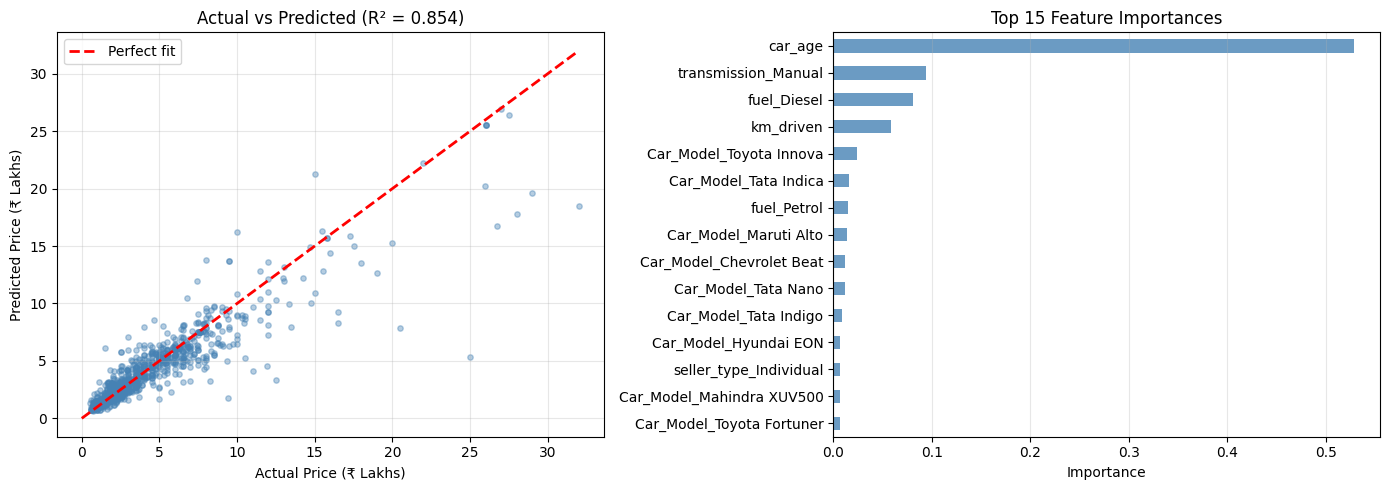

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test_actual/1e5, y_pred_actual/1e5, alpha=0.4, color='steelblue', s=15)
max_val = max(y_test_actual.max(), y_pred_actual.max()) / 1e5
axes[0].plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Perfect fit')
axes[0].set(title=f'Actual vs Predicted (R² = {r2:.3f})',
            xlabel='Actual Price (₹ Lakhs)', ylabel='Predicted Price (₹ Lakhs)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Feature Importance
feat_imp = pd.Series(rf_model.feature_importances_, index=X.columns)
feat_imp.nlargest(15).sort_values().plot(kind='barh', ax=axes[1], color='steelblue', alpha=0.8)
axes[1].set(title='Top 15 Feature Importances', xlabel='Importance')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()


## Section 6: Interactive Price Predictor UI

### 🎛️ Section: Interactive Widget Setup

**Purpose:** Build a UI form using `ipywidgets` so users can input car details and get live predictions, without touching code.

**Extracting dropdown options from raw data**
- `fuel_types`, `trans_types`, `seller_types`, `owners` — unique sorted values pulled directly from `df_raw` (pre-encoding), so the dropdowns show human-readable category labels
- `year_opts` — sorted in **descending** order (`reverse=True`) so the most recent years appear first, a small UX touch

**Mapping one-hot columns back to readable model names**
- `model_column_map` — since `Car_Model` was one-hot encoded earlier (e.g. `Car_Model_Maruti Swift`), this dict reverse-maps the cleaned display name (`Maruti Swift`) back to its actual one-hot column name (`Car_Model_Maruti Swift`)
- This is necessary because the dropdown should show clean names, but the code will later need the exact column name to set the correct one-hot flag to 1
- `model_opts` — sorted list of clean display names for the dropdown

**Widget creation**
- `style = {'description_width': 'initial'}` — ensures widget labels aren't truncated/cut off (common ipywidgets quirk with long labels)
- Dropdowns (`year_dd`, `fuel_dd`, `trans_dd`, `seller_dd`, `owner_dd`, `model_dd`) — one per categorical/discrete input
- `kms_box` (`BoundedIntText`) — numeric input for kilometers driven, constrained between 0–500,000 with step size 500 (prevents invalid/out-of-range entries)

**Action trigger**
- `predict_plot_btn` — styled button that will (in a later cell) trigger prediction + plotting logic when clicked
- `unified_out` — an `Output()` widget, acting as a placeholder container where prediction results/plots will be rendered dynamically (typically cleared and redrawn on each button click)

**Takeaway:** Sets up all input widgets and a trigger button for an interactive "predict price" dashboard — the actual prediction logic and plotting will be wired to `predict_plot_btn`'s click event in the next cell.

In [23]:
fuel_types   = sorted(df_raw['fuel'].unique())
trans_types  = sorted(df_raw['transmission'].unique())
seller_types = sorted(df_raw['seller_type'].unique())
owners       = sorted(df_raw['owner'].unique())
year_opts    = sorted(df_raw['year'].unique(), reverse=True)

model_column_map = {
    c.replace('Car_Model_', ''): c
    for c in df.columns if c.startswith('Car_Model_')
}
model_opts = sorted(model_column_map.keys())

style = {'description_width': 'initial'}
year_dd   = widgets.Dropdown(options=year_opts,   description='Year:',         style=style)
fuel_dd   = widgets.Dropdown(options=fuel_types,  description='Fuel:',         style=style)
trans_dd  = widgets.Dropdown(options=trans_types, description='Transmission:', style=style)
seller_dd = widgets.Dropdown(options=seller_types,description='Seller Type:',  style=style)
owner_dd  = widgets.Dropdown(options=owners,      description='Owner:',        style=style)
model_dd  = widgets.Dropdown(options=model_opts,  description='Car Model:',    style=style)
kms_box   = widgets.BoundedIntText(
    value=30000, min=0, max=500000, step=500,
    description='KMs Driven:', style=style
)

predict_plot_btn = widgets.Button(
    description='Predict & Plot 🚀📊',
    button_style='primary',
    layout=widgets.Layout(width='200px', height='40px')
)
unified_out = widgets.Output()

# ✅ NEW: Dedicated output widget for the final price
result_html = widgets.HTML(value='')

print('✅ Widgets ready')

✅ Widgets ready


### 🔮 Section: Prediction Callback & Trend Plots

**Purpose:** Wire up the "Predict & Plot" button — validates the user's selected combination against real data, builds a model input, predicts price, and shows contextual trend plots for that car model.

**Function setup**
- `predict_and_plot(b)` — callback function; `b` is the button instance passed automatically by `ipywidgets` (unused here, but required by the `on_click` signature)
- `unified_out.clear_output()` + `with unified_out:` — clears previous results and redirects all prints/plots into the same output widget, so repeated clicks refresh cleanly instead of stacking

**Validation chain (before predicting)**
- `model_df` — filters `df_raw` to rows where `name` starts with the selected model prefix, using the *raw* (pre-encoding) data so real-world category combinations can be checked
- Sequentially validates:
  1. Model exists at all in the dataset
  2. Selected fuel type is valid for that model
  3. Selected transmission is valid for that model + fuel combo
  4. Selected seller type is valid for that model
  5. Selected owner type is valid for that model
- Each failed check prints a clear error plus the valid options, then `return`s early — prevents the model from predicting on a combination that never existed in training data (e.g. an EV listed as "Diesel")

**Note:** This is a good practical safeguard — Random Forests will still produce a prediction for nonsensical/unseen combinations, so this manual validation compensates for the model's lack of built-in "out-of-distribution" detection.

**Building the input row**
- `inp` dict initialized with `car_age` and log-transformed `km_driven`
- Loops over each categorical group (`fuel_types`, `trans_types`, `seller_types`, `owners`) to manually set the correct one-hot flag to 1 and others implicitly to 0
- `model_column_map` similarly sets the correct `Car_Model_*` one-hot column
- `for col in X.columns: inp.setdefault(col, 0)` — safety net ensuring every column the model expects is present (missing dummy columns default to 0)
- `input_df = pd.DataFrame([inp])[X.columns]` — reorders columns to exactly match training feature order (critical for sklearn models, which are position/column-order sensitive)

**Prediction**
- `rf_model.predict(input_df)[0]` → log-scale prediction
- `np.expm1(...)` → converts back to actual ₹ price
- Formatted printout summarizing the selected inputs and predicted price (in ₹ and Lakhs)

**Trend plots**
- `plot_df` — subset of raw data for the selected model, with `year`, `km_driven`, `selling_price` coerced to numeric (`errors='coerce'` turns bad values into NaN, then dropped) — defensive cleaning in case of messy raw data
- **Plot 1: Price vs Year** — scatter colored by fuel type, with a regression trend line overlaid (`sns.regplot` with `scatter=False` just draws the fitted line, not duplicate points)
- **Plot 2: Price vs KM Driven** — same structure, showing depreciation trend with distance
- Custom axis formatters (`FuncFormatter`) convert raw numbers into readable ₹ Lakhs / k-KM units on the axes

**Registration**
- `predict_plot_btn.on_click(predict_and_plot)` — binds this function to run whenever the button is clicked

**Takeaway:** This is the core interactive engine of the notebook — it guards against invalid/unseen input combinations, constructs a properly formatted model input row, generates a price prediction, and contextualizes that prediction with real historical trend data for the selected car model.

In [24]:
def predict_and_plot(b):
    unified_out.clear_output()
    result_html.value = '' # ✅ NEW: Clear previous prediction result

    with unified_out:
        selected_model = model_dd.value
        model_col      = model_column_map.get(selected_model)
        car_age        = CURRENT_YEAR - year_dd.value

        # ─── Validation: check if this combo exists in raw data ──────
        prefix   = selected_model + ' '
        model_df = df_raw[df_raw['name'].str.startswith(prefix, na=False)]

        if model_df.empty:
            print(f'❌ No listings found for "{selected_model}" in the dataset.')
            print('   Please select a different car model.')
            return

        # Check fuel type exists for this model
        valid_fuels = model_df['fuel'].unique()
        if fuel_dd.value not in valid_fuels:
            print(f'❌ Invalid combination detected!')
            print(f'   "{selected_model}" is not available with fuel type: {fuel_dd.value}')
            print(f'   ✅ Valid fuel types for this model: {", ".join(sorted(valid_fuels))}')
            return

        # Check transmission exists for this model + fuel combo
        valid_trans = model_df[model_df['fuel'] == fuel_dd.value]['transmission'].unique()
        if trans_dd.value not in valid_trans:
            print(f'❌ Invalid combination detected!')
            print(f'   "{selected_model}" with {fuel_dd.value} fuel is not available')
            print(f'   in {trans_dd.value} transmission.')
            print(f'   ✅ Valid transmissions for this combo: {", ".join(sorted(valid_trans))}')
            return

        # Check seller type exists for this model
        valid_sellers = model_df['seller_type'].unique()
        if seller_dd.value not in valid_sellers:
            print(f'❌ Invalid combination detected!')
            print(f'   "{selected_model}" is not sold by seller type: {seller_dd.value}')
            print(f'   ✅ Valid seller types for this model: {", ".join(sorted(valid_sellers))}')
            return

        # Check owner type exists for this model
        valid_owners = model_df['owner'].unique()
        if owner_dd.value not in valid_owners:
            print(f'❌ Invalid combination detected!')
            print(f'   "{selected_model}" has no listings with owner type: {owner_dd.value}')
            print(f'   ✅ Valid owner types for this model: {", ".join(sorted(valid_owners))}')
            return

        # ─── All checks passed — build input & predict ───────────────
        inp = {
            'car_age':   car_age,
            'km_driven': np.log1p(kms_box.value)
        }
        for f in fuel_types:    inp[f'fuel_{f}']          = int(fuel_dd.value == f)
        for t in trans_types:   inp[f'transmission_{t}']  = int(trans_dd.value == t)
        for s in seller_types:  inp[f'seller_type_{s}']   = int(seller_dd.value == s)
        for o in owners:        inp[f'owner_{o}']          = int(owner_dd.value == o)
        for m, col in model_column_map.items():
            inp[col] = int(m == selected_model)
        for col in X.columns:
            inp.setdefault(col, 0)

        input_df   = pd.DataFrame([inp])[X.columns]
        log_pred   = rf_model.predict(input_df)[0]
        pred_price = np.expm1(log_pred)

        print('=' * 48)
        print(f'  🚗 Model       : {selected_model}')
        print(f'  📅 Year        : {year_dd.value}  (Age: {car_age} yrs)')
        print(f'  ⛽ Fuel        : {fuel_dd.value}')
        print(f'  ⚙️  Transmission: {trans_dd.value}')
        print(f'  📍 KMs Driven  : {kms_box.value:,}')
        print('=' * 48)

        # ✅ NEW: Send the result to the dedicated HTML widget
        result_html.value = f"<h2 style='color: #28a745;'>💰 Predicted Price: ₹{pred_price/100000:.2f} Lakhs (₹{pred_price:,.0f})</h2>"

        # ─── Trend Plots ──────────────────────────────────────────────
        print('\\n📈 Generating price trend plots...')
        plot_df = model_df.copy()
        for col in ['year', 'km_driven', 'selling_price']:
            plot_df[col] = pd.to_numeric(plot_df[col], errors='coerce')
        plot_df.dropna(subset=['year', 'km_driven', 'selling_price'], inplace=True)

        print(f'   📌 {len(plot_df)} listings found for {selected_model}')

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f'{selected_model} — Price Trends', fontsize=14, fontweight='bold')

        sns.scatterplot(data=plot_df, x='year', y='selling_price',
                        hue='fuel', ax=axes[0], alpha=0.7, s=50)
        sns.regplot(data=plot_df, x='year', y='selling_price',
                    ax=axes[0], scatter=False, color='black',
                    line_kws={'linewidth': 2, 'linestyle': '--'})
        axes[0].set(title='Price vs Year', xlabel='Year', ylabel='Price (₹)')
        axes[0].yaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f'₹{x/1e5:.1f}L'))
        axes[0].grid(True, alpha=0.3)

        sns.scatterplot(data=plot_df, x='km_driven', y='selling_price',
                        hue='fuel', ax=axes[1], alpha=0.7, s=50)
        sns.regplot(data=plot_df, x='km_driven', y='selling_price',
                    ax=axes[1], scatter=False, color='black',
                    line_kws={'linewidth': 2, 'linestyle': '--'})
        axes[1].set(title='Price vs KM Driven', xlabel='KM Driven', ylabel='Price (₹)')
        axes[1].yaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f'₹{x/1e5:.1f}L'))
        axes[1].xaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
        axes[1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

predict_plot_btn.on_click(predict_and_plot)
print('✅ Callback registered')

✅ Callback registered


## Section 7: Launch Interactive UI

In [25]:
header = widgets.HTML('<h3 style="color:#2c7be5">🚗 Used Car Price Predictor</h3>')
row1   = widgets.HBox([model_dd, year_dd, kms_box])
row2   = widgets.HBox([fuel_dd, trans_dd, seller_dd, owner_dd])

# ✅ NEW: added result_html to the end of the display parameters
display(header, row1, row2, predict_plot_btn, unified_out, result_html)

HTML(value='<h3 style="color:#2c7be5">🚗 Used Car Price Predictor</h3>')

Button(button_style='primary', description='Predict & Plot 🚀📊', layout=Layout(height='40px', width='200px'), s…

Output()

HTML(value='')